# S1 MF 최종 점수

C2·C3에서 고른 설정으로 `train`을 학습하고, `test`와 `cold_final`로 최종 점수를 **한 번** 잽니다.
이 노트북의 점수로는 설정을 바꾸지 않습니다.

| 목표 | 모델 | 채점 |
| --- | --- | --- |
| Goal 2 기존 독자, 추천 | 추천용 MF | `evaluate_warm(on="test")`, 독자 전원 |
| Goal 2 기존 독자, 별점 | 별점 예측용 MF | `evaluate_rmse(on="test")` |
| Goal 1 신규 독자 | 추천용 MF (fold-in) | `evaluate_cold(on="final")`, 2,500명 |
| Goal 3 읽고 싶은 책 | 추천용 MF | 위 두 추천의 to_read 적중 |

- 최종 채점에서도 모델은 `train`만 학습합니다(`train` + `val`로 다시 학습하지 않음).
  `test` 채점 때 이력으로 넘어오는 `val` 평점은 fold-in이 독자 벡터에 반영합니다.
- 비교 기준으로 인기순을 함께 잽니다.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from bookrec.data import load_split, load_to_read
from bookrec.evaluation import evaluate_cold, evaluate_rmse, evaluate_warm
from bookrec.models.collaborative_filtering import fit_selected_mf
from bookrec.models.collaborative_filtering.tuning import RESULT_DIR, SELECTED_PATH, result_rows
from bookrec.models.popularity import PopularityRecommender
from bookrec.plot_style import MODEL_COLORS, save, setup

setup()
split = load_split()
to_read = load_to_read()
popularity = PopularityRecommender().fit(split.train)
ranking_model = fit_selected_mf("ranking", split.train)
rating_model = fit_selected_mf("rating", split.train)
print("추천용:", ranking_model.config)
# NOTE: vars(객체)는 객체에 저장된 값들을 dict로 돌려준다. 별점 예측용은 ALS일 수 있어 설정 객체 대신 이름과 값을 출력한다.
print("별점 예측용:", type(rating_model).__name__, {key: value for key, value in vars(rating_model).items() if isinstance(value, (int, float))})

추천용: MFConfig(n_factors=128, lr=0.01, reg=0.05, n_epochs=4, batch_size=2048, neg_ratio=8, patience=2, fold_in_reg=10.0, seed=42)
별점 예측용: ALSMatrixFactorization {'n_factors': 64, 'reg': 0.1, 'n_epochs': 25, 'patience': 2, 'seed': 42, 'mu': 3.9351271053557397, 'best_epoch': 25}


## 1. 기존 독자 (Goal 2·3)

In [2]:
warm = {
    "popularity": evaluate_warm(popularity, split, on="test", to_read=to_read),
    "mf_ranking": evaluate_warm(ranking_model, split, on="test", to_read=to_read),
}
warm_table = pd.concat([result_rows(name, "warm_test", result) for name, result in warm.items()], ignore_index=True)
mean_rmse = float(np.sqrt(np.mean((split.test["rating"] - split.train["rating"].mean()) ** 2)))
warm_table["test_rmse"] = np.nan
# NOTE: 별점 예측은 별점 예측용 MF로 잰다(추천 지표는 재지 않아 빈칸으로 둔다).
warm_table.loc[len(warm_table)] = {"model": "mf_rating", "goal": "warm_test", "history_size": "all", "test_rmse": evaluate_rmse(rating_model, split, on="test")}
print(f"전체 평균으로 예측한 test RMSE = {mean_rmse:.4f}")
warm_table.round(4)

전체 평균으로 예측한 test RMSE = 0.9719


,model,goal,history_size,precision@10,recall@10,ndcg@10,users,to_read_hit@10,to_read_users,test_rmse
0,popularity,warm_test,all,0.0268,0.0230,0.0292,48266.0,0.0303,44247.0,NaN
1,mf_ranking,warm_test,all,0.0493,0.0435,0.0549,48266.0,0.0521,44247.0,NaN
2,mf_rating,warm_test,all,NaN,NaN,NaN,NaN,NaN,NaN,0.8515


## 2. 신규 독자 (Goal 1·3)

In [3]:
cold = {
    "popularity": evaluate_cold(popularity, split, on="final", to_read=to_read),
    "mf_ranking": evaluate_cold(ranking_model, split, on="final", to_read=to_read),
}
cold_table = pd.concat([result_rows(name, "cold_final", result) for name, result in cold.items()], ignore_index=True)
cold_table.round(4)

,model,goal,history_size,precision@10,recall@10,ndcg@10,users,to_read_hit@10,to_read_users
0,popularity,cold_final,1,0.2101,0.0308,0.2237,2498,0.0230,2310
1,popularity,cold_final,3,0.2101,0.0308,0.2237,2498,0.0230,2310
2,popularity,cold_final,5,0.2101,0.0308,0.2237,2498,0.0230,2310
3,popularity,cold_final,10,0.2101,0.0308,0.2237,2498,0.0230,2310
4,mf_ranking,cold_final,1,0.2466,0.0362,0.2574,2498,0.0197,2310
5,mf_ranking,cold_final,3,0.2611,0.0387,0.2736,2498,0.0228,2310
6,mf_ranking,cold_final,5,0.2691,0.0401,0.2791,2498,0.0242,2310
7,mf_ranking,cold_final,10,0.2866,0.0430,0.2980,2498,0.0276,2310


In [4]:
final_scores = pd.concat([warm_table, cold_table], ignore_index=True)
final_scores.to_csv(RESULT_DIR / "S1_mf_final_scores.csv", index=False)

saved = json.loads(SELECTED_PATH.read_text())
for purpose in saved:
    saved[purpose]["final_evaluation_performed"] = True
SELECTED_PATH.write_text(json.dumps(saved, indent=2, ensure_ascii=False) + "\n")

1151

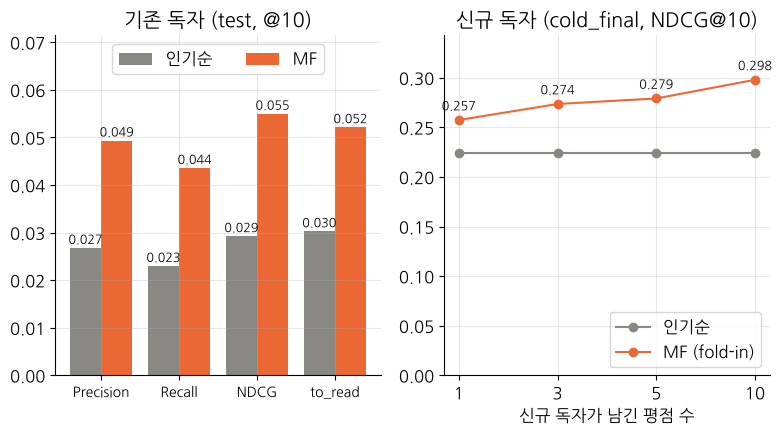

In [5]:
fig, (left, right) = plt.subplots(1, 2)
metrics = ["precision@10", "recall@10", "ndcg@10", "to_read_hit@10"]
position = np.arange(len(metrics))
# NOTE: bar(x 위치, 높이, width)에서 x 위치를 width의 절반만큼 좌우로 옮겨 두 모델의 막대를 나란히 그린다.
left.bar(position - 0.2, [warm["popularity"][metric] for metric in metrics], width=0.4, color=MODEL_COLORS["baseline"], label="인기순")
left.bar(position + 0.2, [warm["mf_ranking"][metric] for metric in metrics], width=0.4, color=MODEL_COLORS["mf"], label="MF")
for x, metric in zip(position, metrics):
    left.annotate(f"{warm['mf_ranking'][metric]:.3f}", (x + 0.2, warm["mf_ranking"][metric]), textcoords="offset points", xytext=(0, 3), ha="center", fontsize=9)
    left.annotate(f"{warm['popularity'][metric]:.3f}", (x - 0.2, warm["popularity"][metric]), textcoords="offset points", xytext=(0, 3), ha="center", fontsize=9)
left.set_xticks(position, ["Precision", "Recall", "NDCG", "to_read"], fontsize=10)
left.set_title("기존 독자 (test, @10)")
# NOTE: 범례가 막대의 숫자를 가리지 않도록 위쪽 여백을 늘리고 범례를 가운데 위에 가로로 둔다.
left.set_ylim(0, max(warm["mf_ranking"][metric] for metric in metrics) * 1.3)
left.legend(loc="upper center", ncol=2)
sizes = cold["mf_ranking"].index.astype(str)
right.plot(sizes, cold["popularity"]["ndcg@10"], color=MODEL_COLORS["baseline"], marker="o", label="인기순")
right.plot(sizes, cold["mf_ranking"]["ndcg@10"], color=MODEL_COLORS["mf"], marker="o", label="MF (fold-in)")
for x, y in zip(sizes, cold["mf_ranking"]["ndcg@10"]):
    right.annotate(f"{y:.3f}", (x, y), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=9)
# NOTE: 위쪽에 여백을 둬서 숫자 표시가 제목과 겹치지 않게 한다.
right.set_ylim(0, cold["mf_ranking"]["ndcg@10"].max() * 1.15)
right.set_xlabel("신규 독자가 남긴 평점 수")
right.set_title("신규 독자 (cold_final, NDCG@10)")
right.legend(loc="lower right")
save(fig, "S1_mf_final_scores")
plt.show()